# COMP4318/5318 Assignment 2: Image Classification

### Group number: 217  , SID1: STUDENT_ID_REDACTED , SID2: ..., SID3: ..., SID4: ...

This template notebook includes code to load the  dataset and a skeleton for the main sections that should be included in the notebook. Please stick to this struture for your submitted notebook.

Please focus on making your code clear, with appropriate variable names and whitespace. Include comments and markdown text to aid the readability of your code where relevant. See the specification and marking criteria in the associated specification to guide you when completing your implementation.

## Setup and dependencies
Please use this section to list and set up all your required libraries/dependencies and your plotting environment.

In [1]:
# Import libraries for data handling, visualisation, splitting, and evaluation
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

# Set a fixed random seed so that the validation split and experiments are reproducible
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Use a consistent plotting style throughout the notebook
plt.style.use("seaborn-v0_8-whitegrid")

## 1. Data loading, exploration, and preprocessing

Code to load the dataset is provided in the following cell. Please proceed with your data exploration and preprocessing in the remainder of this section.

In [2]:
# Load the dataset training and test sets as numpy arrays
# assuming Assignment2Data folder is present in the same directory 
# as the notebook
X_train = np.load('Assignment2Data/X_train.npy')
y_train = np.load('Assignment2Data/y_train.npy')
X_test = np.load('Assignment2Data/X_test.npy')
y_test = np.load('Assignment2Data/y_test.npy')

### 1.1 Data validation and summary

Before preprocessing, we verify the relationship between the images and labels, inspect the array shapes and data types, and confirm the expected image and class structure. These checks detect path, shape, or label errors before any model is trained.

In [3]:
# Keep explicit references to the unmodified uint8 arrays
X_train_raw = X_train
y_train_raw = y_train
X_test_raw = X_test
y_test_raw = y_test

# Validate that each image has exactly one corresponding label
assert X_train_raw.shape[0] == y_train_raw.shape[0], "Training images and labels do not match."
assert X_test_raw.shape[0] == y_test_raw.shape[0], "Test images and labels do not match."

# Validate the expected 28 x 28 RGB image format and integer labels

assert X_train_raw.shape[1:] == (28, 28, 3), "Unexpected training image shape."
assert X_test_raw.shape[1:] == (28, 28, 3), "Unexpected test image shape."
assert y_train_raw.ndim == 1 and y_test_raw.ndim == 1, "Labels must be one-dimensional."

train_classes = np.unique(y_train_raw)
test_classes = np.unique(y_test_raw)

# The supplied training and test sets should contain the same nine classes
assert np.array_equal(train_classes, test_classes), "Training and test classes do not match."
assert np.array_equal(train_classes, np.arange(9)), "Expected class labels 0 to 8."

dataset_summary = pd.DataFrame(
    {
        "Split": ["Training", "Test"],
        "Samples": [len(X_train_raw), len(X_test_raw)],
        "Image shape": [str(X_train_raw.shape[1:]), str(X_test_raw.shape[1:])],
        "Image dtype": [str(X_train_raw.dtype), str(X_test_raw.dtype)],
        "Pixel minimum": [X_train_raw.min(), X_test_raw.min()],
        "Pixel maximum": [X_train_raw.max(), X_test_raw.max()],
        "Number of classes": [len(train_classes), len(test_classes)],
    }
)

display(dataset_summary)
print("Class labels:", train_classes)
print("Dataset validation completed successfully.")

,Split,Samples,Image shape,Image dtype,Pixel minimum,Pixel maximum,Number of classes
0,Training,32000,"(28, 28, 3)",uint8,0,255,9
1,Test,8000,"(28, 28, 3)",uint8,0,255,9


Class labels: [0 1 2 3 4 5 6 7 8]
Dataset validation completed successfully.


### 1.2 Class distribution

Class counts and proportions are inspected separately for the supplied training and test sets. This identifies class imbalance and checks whether accuracy alone will be sufficient for evaluation. The supplied test set is inspected descriptively here but is not used to choose preprocessing settings, architectures, or hyperparameters.

,Split,Class ID,Class name,Count,Proportion
0,Training,0,Adipose,3490,0.109063
1,Training,1,Background,3431,0.107219
2,Training,2,Debris,3505,0.109531
3,Training,3,Lymphocytes,3656,0.114250
4,Training,4,Mucus,2950,0.092188
5,Training,5,Smooth muscle,4290,0.134063
6,Training,6,Normal colon mucosa,2728,0.085250
7,Training,7,Cancer-associated stroma,3253,0.101656
8,Training,8,Colorectal adenocarcinoma epithelium,4697,0.146781
9,Test,0,Adipose,873,0.109125


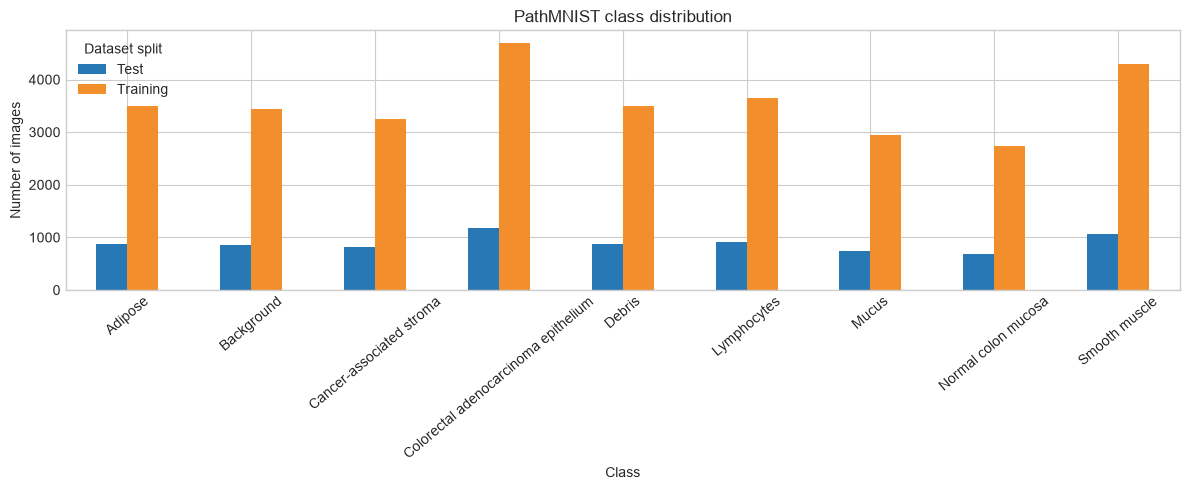

In [4]:
# PathMNIST class names corresponding to labels 0-8
CLASS_NAMES = {
    0: "Adipose",
    1: "Background",
    2: "Debris",
    3: "Lymphocytes",
    4: "Mucus",
    5: "Smooth muscle",
    6: "Normal colon mucosa",
    7: "Cancer-associated stroma",
    8: "Colorectal adenocarcinoma epithelium",
}

def build_class_distribution(labels, split_name):
    # Return class counts and proportions for one dataset split.
    class_ids, counts = np.unique(labels, return_counts=True)
    return pd.DataFrame(
        {
            "Split": split_name,
            "Class ID": class_ids,
            "Class name": [CLASS_NAMES[class_id] for class_id in class_ids],
            "Count": counts,
            "Proportion": counts / len(labels),
        }
    )

class_distribution = pd.concat(
    [
        build_class_distribution(y_train_raw, "Training"),
        build_class_distribution(y_test_raw, "Test"),
    ],
    ignore_index=True,
)

display(class_distribution)

# Plot training and test counts side by side for an immediate imbalance check
distribution_pivot = class_distribution.pivot(
    index="Class name", columns="Split", values="Count"
)
ax = distribution_pivot.plot(kind="bar", figsize=(12, 5), color=["#2878B5", "#F28E2B"])
ax.set_title("PathMNIST class distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=40)
ax.legend(title="Dataset split")
plt.tight_layout()
plt.show()

### 1.3 Visual exploration of the images

One reproducibly selected image from each class is displayed to inspect colour, texture, centring, and visual similarities between tissue categories. Mean images are also shown to reveal class-level colour and structural tendencies that may not be obvious from individual samples.

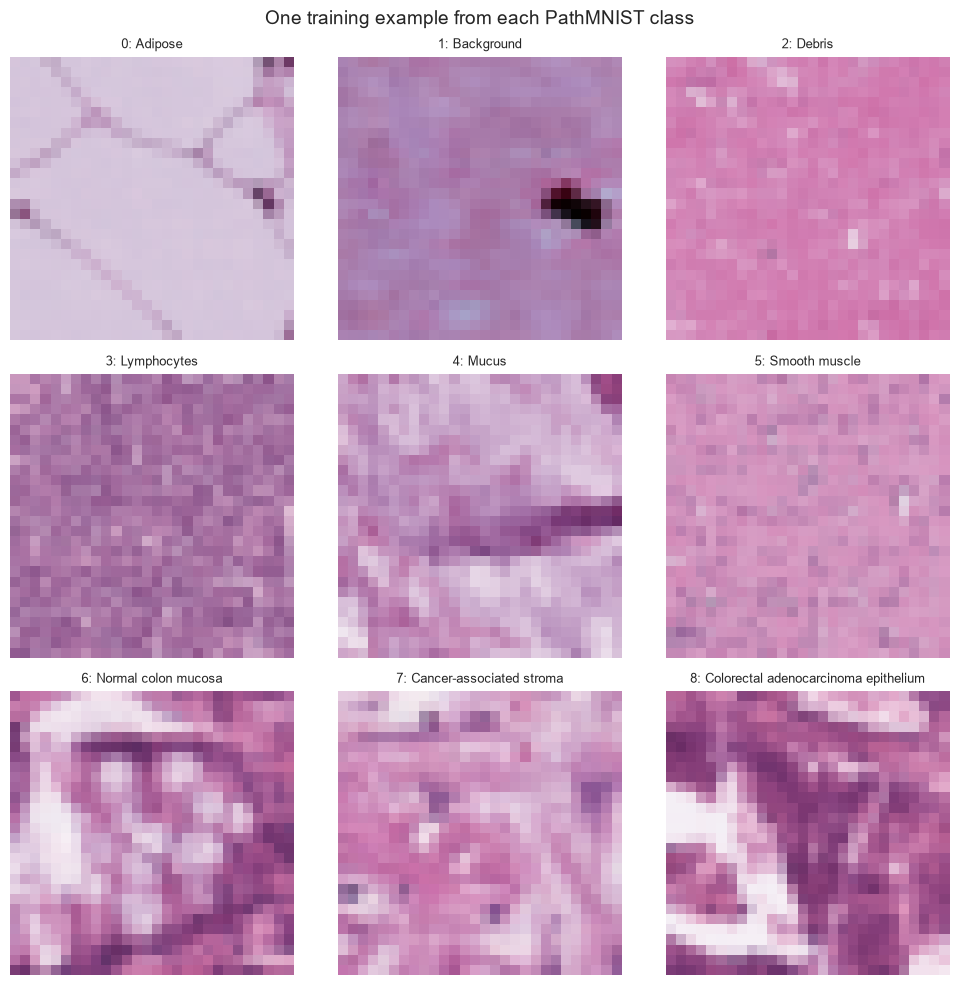

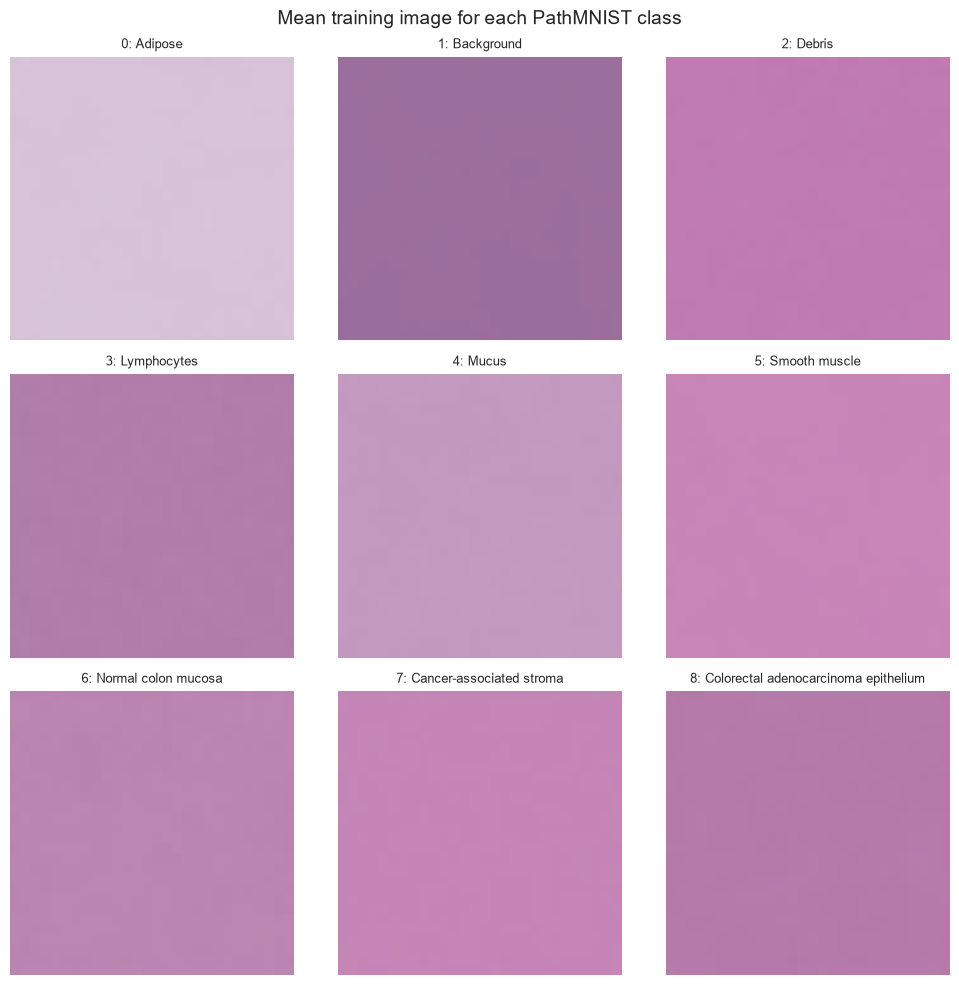

In [5]:
# Use a dedicated generator so image selection is reproducible without changing other experiments
sample_rng = np.random.default_rng(RANDOM_STATE)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for class_id, ax in zip(train_classes, axes.flat):
    class_indices = np.flatnonzero(y_train_raw == class_id)
    sample_index = sample_rng.choice(class_indices)
    ax.imshow(X_train_raw[sample_index])
    ax.set_title(f"{class_id}: {CLASS_NAMES[class_id]}", fontsize=9)
    ax.axis("off")

fig.suptitle("One training example from each PathMNIST class", fontsize=14)
plt.tight_layout()
plt.show()

# Average all images within each class to expose broad colour and structural patterns
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for class_id, ax in zip(train_classes, axes.flat):
    mean_image = X_train_raw[y_train_raw == class_id].mean(axis=0).astype(np.uint8)
    ax.imshow(mean_image)
    ax.set_title(f"{class_id}: {CLASS_NAMES[class_id]}", fontsize=9)
    ax.axis("off")

fig.suptitle("Mean training image for each PathMNIST class", fontsize=14)
plt.tight_layout()
plt.show()

### 1.4 Pixel-intensity exploration

Global and channel-wise statistics are calculated to determine the numeric scale and colour characteristics of the images. A subsample is used for the histogram to keep plotting efficient while retaining a representative view of the intensity distribution.

,Channel,Mean,Standard deviation,Minimum,Maximum
0,Red,188.65,31.91,0,255
1,Green,135.93,45.60,0,252
2,Blue,180.05,32.18,0,255


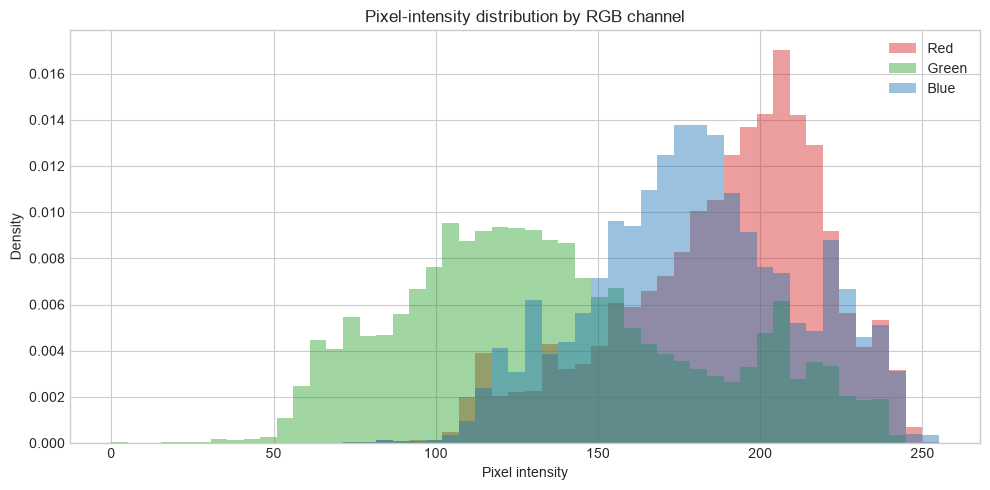

,Class ID,Class name,Mean intensity,Intensity standard deviation
0,0,Adipose,208.67,26.35
1,1,Background,140.97,55.89
2,2,Debris,164.57,41.09
3,3,Lymphocytes,157.37,36.42
4,4,Mucus,180.28,34.59
5,5,Smooth muscle,172.24,40.23
6,6,Normal colon mucosa,165.66,41.93
7,7,Cancer-associated stroma,171.08,34.98
8,8,Colorectal adenocarcinoma epithelium,157.46,41.72


In [6]:
# Compute channel statistics across all training images and spatial positions
channel_names = ["Red", "Green", "Blue"]
channel_statistics = pd.DataFrame(
    {
        "Channel": channel_names,
        "Mean": X_train_raw.mean(axis=(0, 1, 2)),
        "Standard deviation": X_train_raw.std(axis=(0, 1, 2)),
        "Minimum": X_train_raw.min(axis=(0, 1, 2)),
        "Maximum": X_train_raw.max(axis=(0, 1, 2)),
    }
)
display(channel_statistics.round(2))

# Sample every twentieth image to make histogram calculation memory-efficient
pixel_sample = X_train_raw[::20]
channel_colours = ["#D62728", "#2CA02C", "#1F77B4"]

fig, ax = plt.subplots(figsize=(10, 5))
for channel_index, (channel_name, colour) in enumerate(zip(channel_names, channel_colours)):
    ax.hist(
        pixel_sample[..., channel_index].ravel(),
        bins=50,
        range=(0, 255),
        density=True,
        alpha=0.45,
        color=colour,
        label=channel_name,
    )

ax.set_title("Pixel-intensity distribution by RGB channel")
ax.set_xlabel("Pixel intensity")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

# Compare average image intensity across classes as a compact numerical summary
class_intensity_summary = pd.DataFrame(
    {
        "Class ID": train_classes,
        "Class name": [CLASS_NAMES[class_id] for class_id in train_classes],
        "Mean intensity": [
            X_train_raw[y_train_raw == class_id].mean() for class_id in train_classes
        ],
        "Intensity standard deviation": [
            X_train_raw[y_train_raw == class_id].std() for class_id in train_classes
        ],
    }
)
display(class_intensity_summary.round(2))

### 1.5 Preprocessing and stratified validation split

The supplied test set is reserved exclusively for the final comparison. A validation set is therefore created only from the supplied training data. Stratification preserves the class proportions in both subsets. Pixel values are converted from unsigned 8-bit integers in `[0, 255]` to `float32` values in `[0, 1]`, which gives neural-network optimisation a stable numeric scale and supplies a consistent representation to all models.

Two representations are prepared without altering the source arrays:

- `*_images`: shape `(n, 28, 28, 3)` for the CNN.
- `*_flat`: shape `(n, 2352)` for the first-six-weeks classifier and MLP.

In [7]:
# Reserve 20% of the supplied training data for validation
VALIDATION_SIZE = 0.20
all_training_indices = np.arange(len(X_train_raw))

train_indices, validation_indices = train_test_split(
    all_training_indices,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_train_raw,
)

# Split first, then convert and normalise each subset to avoid modifying the source arrays
X_train_images = X_train_raw[train_indices].astype(np.float32) / 255.0
X_validation_images = X_train_raw[validation_indices].astype(np.float32) / 255.0
X_test_images = X_test_raw.astype(np.float32) / 255.0

y_train_split = y_train_raw[train_indices].astype(np.int64)
y_validation = y_train_raw[validation_indices].astype(np.int64)
y_test_final = y_test_raw.astype(np.int64)

# Flattening creates model-ready feature matrices while retaining the same samples
X_train_flat = X_train_images.reshape(len(X_train_images), -1)
X_validation_flat = X_validation_images.reshape(len(X_validation_images), -1)
X_test_flat = X_test_images.reshape(len(X_test_images), -1)

# Confirm that preprocessing produced the intended ranges and shapes
assert 0.0 <= X_train_images.min() <= X_train_images.max() <= 1.0
assert 0.0 <= X_validation_images.min() <= X_validation_images.max() <= 1.0
assert 0.0 <= X_test_images.min() <= X_test_images.max() <= 1.0
assert X_train_flat.shape[1] == 28 * 28 * 3
assert X_validation_flat.shape[1] == 28 * 28 * 3
assert X_test_flat.shape[1] == 28 * 28 * 3

preprocessing_summary = pd.DataFrame(
    {
        "Subset": ["Training", "Validation", "Test"],
        "Samples": [len(y_train_split), len(y_validation), len(y_test_final)],
        "Image input shape": [
            str(X_train_images.shape),
            str(X_validation_images.shape),
            str(X_test_images.shape),
        ],
        "Flattened input shape": [
            str(X_train_flat.shape),
            str(X_validation_flat.shape),
            str(X_test_flat.shape),
        ],
        "Minimum": [
            X_train_images.min(),
            X_validation_images.min(),
            X_test_images.min(),
        ],
        "Maximum": [
            X_train_images.max(),
            X_validation_images.max(),
            X_test_images.max(),
        ],
    }
)
display(preprocessing_summary)

# Check that stratification kept class proportions nearly unchanged
split_distribution = pd.concat(
    [
        build_class_distribution(y_train_split, "Training split"),
        build_class_distribution(y_validation, "Validation split"),
    ],
    ignore_index=True,
)
display(
    split_distribution.pivot(
        index=["Class ID", "Class name"],
        columns="Split",
        values="Proportion",
    ).round(4)
)

print("Preprocessing and stratified validation split completed successfully.")

,Subset,Samples,Image input shape,Flattened input shape,Minimum,Maximum
0,Training,25600,"(25600, 28, 28, 3)","(25600, 2352)",0.0,1.0
1,Validation,6400,"(6400, 28, 28, 3)","(6400, 2352)",0.0,1.0
2,Test,8000,"(8000, 28, 28, 3)","(8000, 2352)",0.0,1.0


,Split,Training split,Validation split
Class ID,Class name,,
0,Adipose,0.1091,0.1091
1,Background,0.1072,0.1072
2,Debris,0.1095,0.1095
3,Lymphocytes,0.1143,0.1142
4,Mucus,0.0922,0.0922
5,Smooth muscle,0.1341,0.1341
6,Normal colon mucosa,0.0852,0.0853
7,Cancer-associated stroma,0.1016,0.1017
8,Colorectal adenocarcinoma epithelium,0.1468,0.1467


Preprocessing and stratified validation split completed successfully.


### Examples of preprocessed data

The comparison below verifies that normalisation changes the numeric scale but does not alter the visual content. The original image is stored as `uint8` in `[0, 255]`, while the model-ready image is stored as `float32` in `[0, 1]`.

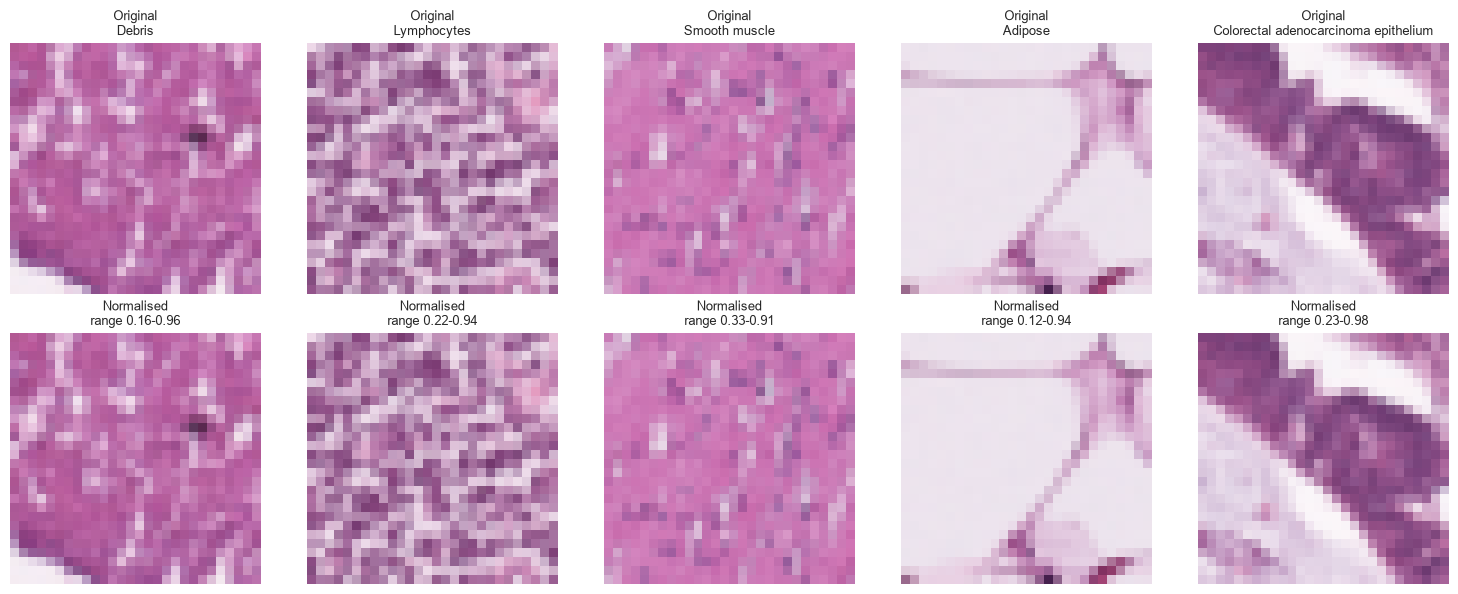

In [8]:
# Compare the original and normalised versions of the same training examples
example_indices = train_indices[:5]
fig, axes = plt.subplots(2, len(example_indices), figsize=(15, 6))

for column, original_index in enumerate(example_indices):
    axes[0, column].imshow(X_train_raw[original_index])
    axes[0, column].set_title(
        f"Original\n{CLASS_NAMES[int(y_train_raw[original_index])]}", fontsize=9
    )
    axes[0, column].axis("off")

    axes[1, column].imshow(X_train_images[column])
    axes[1, column].set_title(
        f"Normalised\nrange {X_train_images[column].min():.2f}-{X_train_images[column].max():.2f}",
        fontsize=9,
    )
    axes[1, column].axis("off")

plt.tight_layout()
plt.show()

### 1.6 Shared evaluation utilities

The functions below give all three models a consistent evaluation procedure. They report accuracy and macro-averaged precision, recall, and F1-score, then display a per-class classification report and confusion matrix. Macro averages give every tissue class equal importance, which is useful when class frequencies differ. Prediction runtime is measured separately from training runtime.

In [9]:
def convert_predictions_to_labels(predictions):
    """Convert class probabilities or class IDs into a one-dimensional label array."""
    predictions = np.asarray(predictions)
    if predictions.ndim == 2:
        return np.argmax(predictions, axis=1)
    return predictions.astype(np.int64).ravel()

def evaluate_predictions(y_true, predictions, model_name, prediction_time=None):
    """Calculate metrics and plot a confusion matrix for one model."""
    y_pred = convert_predictions_to_labels(predictions)
    labels = np.arange(len(CLASS_NAMES))

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro precision": precision_score(
            y_true, y_pred, labels=labels, average="macro", zero_division=0
        ),
        "Macro recall": recall_score(
            y_true, y_pred, labels=labels, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, labels=labels, average="macro", zero_division=0
        ),
        "Prediction time (s)": prediction_time,
    }

    display(pd.DataFrame([metrics]).round(4))
    print(
        classification_report(
            y_true,
            y_pred,
            labels=labels,
            target_names=[CLASS_NAMES[label] for label in labels],
            digits=4,
            zero_division=0,
        )
    )

    matrix = confusion_matrix(y_true, y_pred, labels=labels)
    display_labels = [f"{label}: {CLASS_NAMES[label]}" for label in labels]
    figure, axis = plt.subplots(figsize=(11, 9))
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=display_labels,
    ).plot(ax=axis, cmap="Blues", values_format="d", colorbar=False)
    axis.set_title(f"Confusion matrix: {model_name}")
    axis.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()

    return metrics, y_pred

def predict_and_evaluate(model, X_evaluation, y_evaluation, model_name, **predict_kwargs):
    """Time model prediction and apply the shared evaluation procedure."""
    start_time = perf_counter()
    predictions = model.predict(X_evaluation, **predict_kwargs)
    prediction_time = perf_counter() - start_time
    return evaluate_predictions(
        y_evaluation,
        predictions,
        model_name=model_name,
        prediction_time=prediction_time,
    )

def plot_training_history(history, model_name):
    """Plot training and validation accuracy and loss from a Keras History object."""
    history_values = history.history
    epochs = np.arange(1, len(history_values["loss"]) + 1)

    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history_values["accuracy"], label="Training")
    axes[0].plot(epochs, history_values["val_accuracy"], label="Validation")
    axes[0].set_title(f"{model_name}: accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].plot(epochs, history_values["loss"], label="Training")
    axes[1].plot(epochs, history_values["val_loss"], label="Validation")
    axes[1].set_title(f"{model_name}: loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

> **Data-leakage control**
> The validation split is used for model design and hyperparameter selection. The supplied test set must remain untouched until each final model has been fixed and independently trained. Test performance must not be used to revise hyperparameters.
>

## 2. Algorithm design and setup

### Algorithm of choice from first six weeks of course

### Fully connected neural network

The MLP takes 2,352 normalised pixel features as input. Hidden
layers use ReLU activations, and the output layer uses softmax
to predict probabilities for the nine tissue classes. The model
is trained with Adam and sparse categorical cross-entropy,
which accepts integer class labels.

Unlike a CNN, this fully connected model does not explicitly
exploit local spatial structure or share weights across image
locations.

In [11]:
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(RANDOM_STATE)

In [12]:
def build_mlp(hidden_units=(128,), learning_rate=0.001):
    # Each image has already been flattened into 2352 features.
    model = keras.Sequential()
    model.add(keras.Input(shape=(2352,)))

    # Add one or more fully connected hidden layers.
    for units in hidden_units:
        model.add(layers.Dense(units, activation="relu"))

    # Predict probabilities for the nine tissue classes.
    model.add(layers.Dense(9, activation="softmax"))

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model


mlp_initial = build_mlp()
mlp_initial.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       301,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 302,345 (1.15 MB)

 Trainable params: 302,345 (1.15 MB)

 Non-trainable params: 0 (0.00 B)

### Convolutional neural network

## 3. Hyperparameter tuning

### Algorithm of choice from first six weeks of course

### Fully connected neural network

In [13]:
from sklearn.model_selection import ParameterGrid

# Search three hyperparameters: architecture, learning rate, and batch size.
mlp_param_grid = {
    "hidden_units": [(128,), (256, 128)],
    "learning_rate": [0.001, 0.0003],
    "batch_size": [64, 128],
}

mlp_search_results = []
mlp_combinations = list(ParameterGrid(mlp_param_grid))

for trial, params in enumerate(mlp_combinations, start=1):
    keras.backend.clear_session()
    keras.utils.set_random_seed(RANDOM_STATE)

    model = build_mlp(
        hidden_units=params["hidden_units"],
        learning_rate=params["learning_rate"],
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=3,
        restore_best_weights=True,
    )

    print(
        f"\nTrial {trial}/{len(mlp_combinations)}: {params}",
        flush=True,
    )

    start_time = perf_counter()

    history = model.fit(
        X_train_flat,
        y_train_split,
        validation_data=(X_validation_flat, y_validation),
        epochs=20,
        batch_size=params["batch_size"],
        callbacks=[early_stopping],
        verbose=2,
    )

    training_time = perf_counter() - start_time

    val_loss, val_accuracy = model.evaluate(
        X_validation_flat,
        y_validation,
        verbose=0,
    )

    mlp_search_results.append({
        **params,
        "validation_accuracy": val_accuracy,
        "validation_loss": val_loss,
        "training_time_s": training_time,
        "epochs_run": len(history.history["loss"]),
        "best_epoch": int(
            np.argmax(history.history["val_accuracy"]) + 1
        ),
    })

    # Save each completed trial so results survive a kernel restart.
    pd.DataFrame(mlp_search_results).to_csv(
        "mlp_tuning_results.csv",
        index=False,
    )

mlp_results_df = pd.DataFrame(mlp_search_results).sort_values(
    "validation_accuracy",
    ascending=False,
).reset_index(drop=True)

display(mlp_results_df)



Trial 1/8: {'batch_size': 64, 'hidden_units': (128,), 'learning_rate': 0.001}
Epoch 1/20
400/400 - 2s - 4ms/step - accuracy: 0.2423 - loss: 1.9990 - val_accuracy: 0.2577 - val_loss: 1.8982
Epoch 2/20
400/400 - 1s - 2ms/step - accuracy: 0.2947 - loss: 1.8455 - val_accuracy: 0.3252 - val_loss: 1.7968
Epoch 3/20
400/400 - 1s - 3ms/step - accuracy: 0.3416 - loss: 1.7596 - val_accuracy: 0.3686 - val_loss: 1.7205
Epoch 4/20
400/400 - 1s - 2ms/step - accuracy: 0.3766 - loss: 1.6836 - val_accuracy: 0.3894 - val_loss: 1.6406
Epoch 5/20
400/400 - 1s - 2ms/step - accuracy: 0.4036 - loss: 1.6252 - val_accuracy: 0.3994 - val_loss: 1.5959
Epoch 6/20
400/400 - 1s - 2ms/step - accuracy: 0.4178 - loss: 1.5865 - val_accuracy: 0.4202 - val_loss: 1.5720
Epoch 7/20
400/400 - 1s - 2ms/step - accuracy: 0.4288 - loss: 1.5619 - val_accuracy: 0.4311 - val_loss: 1.5419
Epoch 8/20
400/400 - 1s - 2ms/step - accuracy: 0.4343 - loss: 1.5390 - val_accuracy: 0.4309 - val_loss: 1.5192
Epoch 9/20
400/400 - 1s - 2ms/st

,batch_size,hidden_units,learning_rate,validation_accuracy,validation_loss,training_time_s,epochs_run,best_epoch
0,64,"(256, 128)",0.0010,0.534375,1.233429,24.665515,19,16
1,128,"(256, 128)",0.0003,0.510156,1.326362,17.089347,20,17
2,64,"(128,)",0.0010,0.505313,1.373870,18.217760,20,18
3,128,"(256, 128)",0.0010,0.491406,1.356511,10.538627,12,9
4,64,"(256, 128)",0.0003,0.489688,1.368194,14.551399,11,8
5,64,"(128,)",0.0003,0.465937,1.421222,17.552331,20,20
6,128,"(128,)",0.0010,0.446094,1.508518,10.400500,19,16
7,128,"(128,)",0.0003,0.428594,1.551423,11.039145,20,20


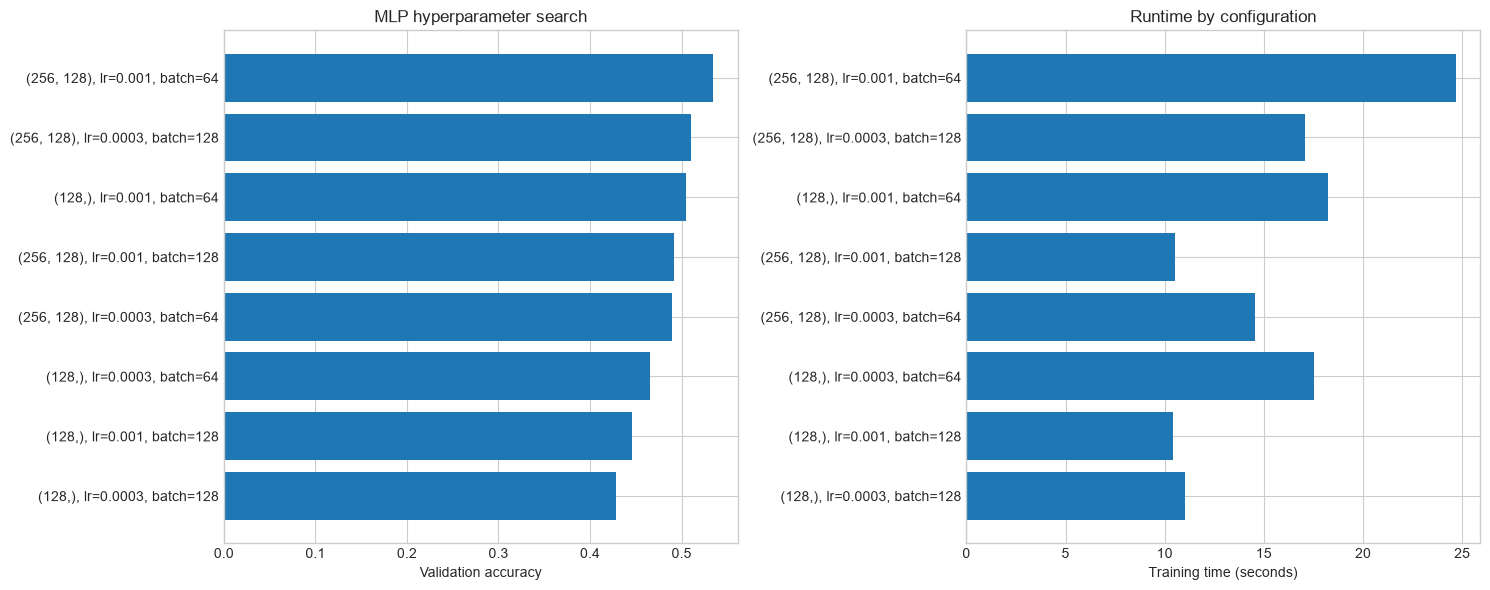

In [17]:
# Compare validation accuracy and runtime for all eight configurations.
plot_results = mlp_results_df.copy()

plot_results["Configuration"] = plot_results.apply(
    lambda row: (
        f"{row['hidden_units']}, "
        f"lr={row['learning_rate']}, "
        f"batch={row['batch_size']}"
    ),
    axis=1,
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].barh(
    plot_results["Configuration"],
    plot_results["validation_accuracy"],
)
axes[0].set_xlabel("Validation accuracy")
axes[0].set_title("MLP hyperparameter search")
axes[0].invert_yaxis()

axes[1].barh(
    plot_results["Configuration"],
    plot_results["training_time_s"],
)
axes[1].set_xlabel("Training time (seconds)")
axes[1].set_title("Runtime by configuration")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

A validation-set grid search compared eight configurations,
varying hidden-layer architecture, learning rate, and batch size.
Each model was trained for up to 20 epochs. Early stopping
monitored validation accuracy with a patience of three epochs
and restored the best weights.

The best configuration used hidden layers of 256 and 128 units,
a learning rate of 0.001, and a batch size of 64. It achieved
53.44% validation accuracy and took approximately 24.67 seconds
to train. Larger models did not consistently perform better
across all configurations. Runtime comparisons also depend on
the number of epochs completed before early stopping.

### Convolutional neural network

## 4. Final models
In this section, please ensure to include cells to train each model with its best hyperparmater combination independently of the hyperparameter tuning cells, i.e. don't rely on the hyperparameter tuning cells having been run.

### Algorithm of choice from first six weeks of course

### Fully connected neural network

In [14]:
# Best configuration selected using validation accuracy.
# Explicit values allow this cell to run without the search cell.
MLP_FINAL_PARAMS = {
    "hidden_units": (256, 128),
    "learning_rate": 0.001,
    "batch_size": 64,
}

keras.backend.clear_session()
keras.utils.set_random_seed(RANDOM_STATE)

mlp_final = build_mlp(
    hidden_units=MLP_FINAL_PARAMS["hidden_units"],
    learning_rate=MLP_FINAL_PARAMS["learning_rate"],
)

mlp_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=3,
    restore_best_weights=True,
)

start_time = perf_counter()

mlp_final_history = mlp_final.fit(
    X_train_flat,
    y_train_split,
    validation_data=(X_validation_flat, y_validation),
    epochs=20,
    batch_size=MLP_FINAL_PARAMS["batch_size"],
    callbacks=[mlp_early_stopping],
    verbose=2,
)

mlp_final_training_time = perf_counter() - start_time

print(f"Training time: {mlp_final_training_time:.2f} seconds") 

Epoch 1/20
400/400 - 2s - 5ms/step - accuracy: 0.2795 - loss: 1.8893 - val_accuracy: 0.3834 - val_loss: 1.6829
Epoch 2/20
400/400 - 1s - 3ms/step - accuracy: 0.3800 - loss: 1.6253 - val_accuracy: 0.4286 - val_loss: 1.5404
Epoch 3/20
400/400 - 1s - 3ms/step - accuracy: 0.4397 - loss: 1.4989 - val_accuracy: 0.4548 - val_loss: 1.4405
Epoch 4/20
400/400 - 1s - 3ms/step - accuracy: 0.4655 - loss: 1.4380 - val_accuracy: 0.4819 - val_loss: 1.3836
Epoch 5/20
400/400 - 1s - 3ms/step - accuracy: 0.4763 - loss: 1.4035 - val_accuracy: 0.4909 - val_loss: 1.3470
Epoch 6/20
400/400 - 1s - 3ms/step - accuracy: 0.4812 - loss: 1.3877 - val_accuracy: 0.4827 - val_loss: 1.3663
Epoch 7/20
400/400 - 1s - 4ms/step - accuracy: 0.4862 - loss: 1.3675 - val_accuracy: 0.4952 - val_loss: 1.3320
Epoch 8/20
400/400 - 2s - 4ms/step - accuracy: 0.4935 - loss: 1.3475 - val_accuracy: 0.4952 - val_loss: 1.3230
Epoch 9/20
400/400 - 1s - 3ms/step - accuracy: 0.5012 - loss: 1.3326 - val_accuracy: 0.5030 - val_loss: 1.3017
E

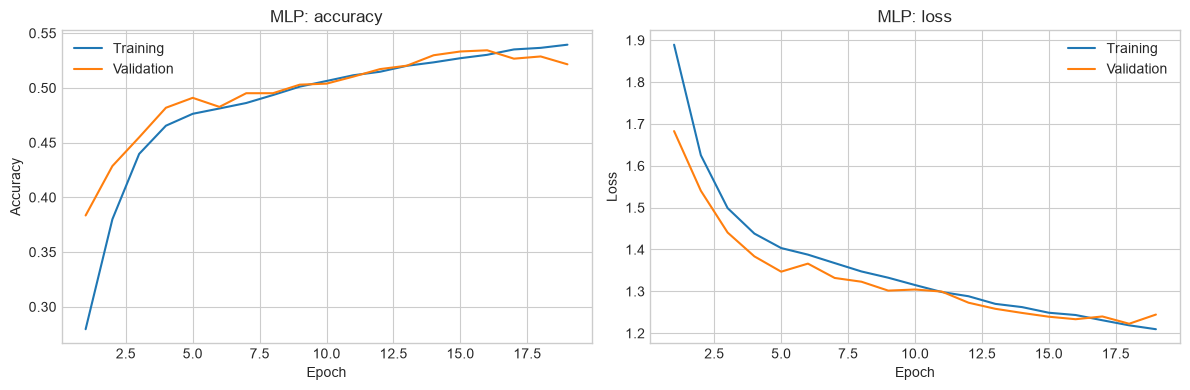

In [15]:
plot_training_history(
    mlp_final_history,
    model_name="MLP",
)

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Prediction time (s)
0,MLP,0.5384,0.5192,0.522,0.5023,0.7513


                                      precision    recall  f1-score   support

                             Adipose     0.7124    0.9759    0.8236       873
                          Background     0.8800    0.7692    0.8209       858
                              Debris     0.3780    0.3637    0.3707       877
                         Lymphocytes     0.4913    0.7702    0.5999       914
                               Mucus     0.6045    0.4749    0.5319       737
                       Smooth muscle     0.5336    0.4590    0.4935      1072
                 Normal colon mucosa     0.2997    0.1349    0.1860       682
            Cancer-associated stroma     0.3322    0.1181    0.1742       813
Colorectal adenocarcinoma epithelium     0.4417    0.6320    0.5200      1174

                            accuracy                         0.5384      8000
                           macro avg     0.5192    0.5220    0.5023      8000
                        weighted avg     0.5210    0.5384    0

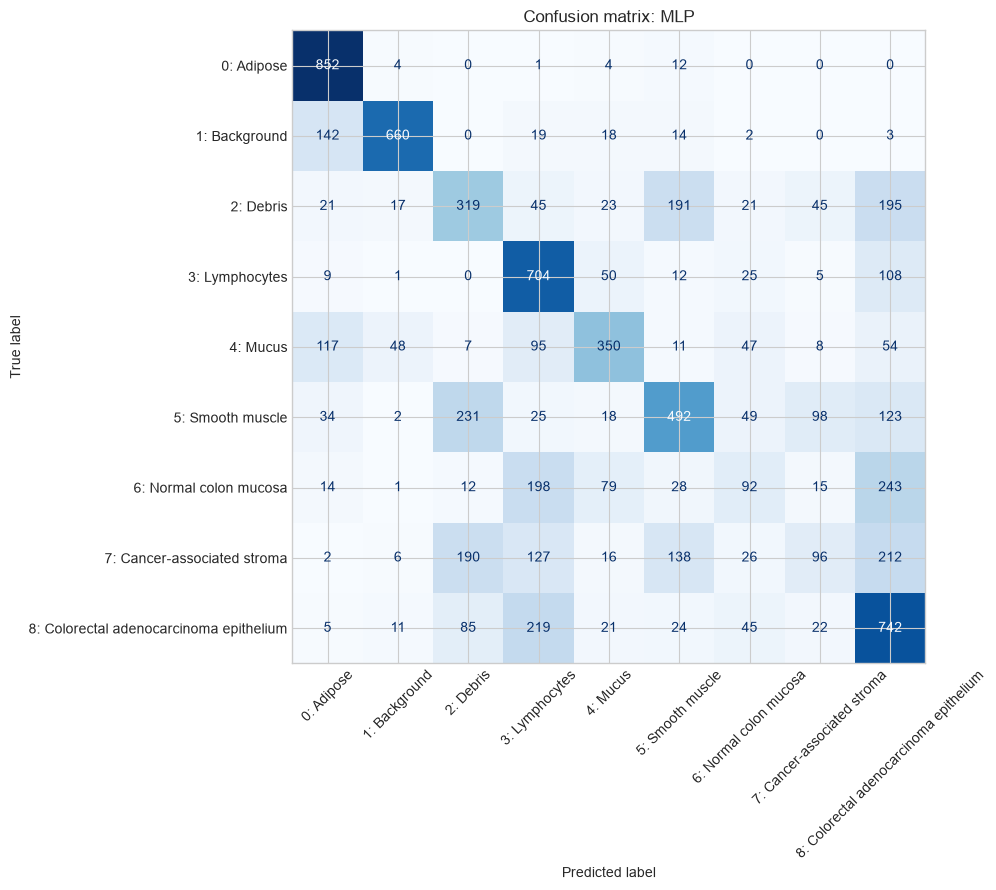

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Prediction time (s),Training time (s),Parameters,Epochs run
0,MLP,0.538375,0.51925,0.522002,0.502306,0.751328,25.703805,636425,19


In [16]:
mlp_metrics, mlp_test_predictions = predict_and_evaluate(
    model=mlp_final,
    X_evaluation=X_test_flat,
    y_evaluation=y_test_final,
    model_name="MLP",
    verbose=0,
)

mlp_metrics["Training time (s)"] = mlp_final_training_time
mlp_metrics["Parameters"] = mlp_final.count_params()
mlp_metrics["Epochs run"] = len(mlp_final_history.history["loss"])

display(pd.DataFrame([mlp_metrics]))

# Save final metrics for the group comparison.
pd.DataFrame([mlp_metrics]).to_csv(
    "mlp_final_results.csv",
    index=False,
)

The independently trained final MLP achieved 53.84% test accuracy
and a macro F1-score of 0.5023. Training took approximately
25.70 seconds, and prediction on 8,000 test images took
approximately 0.75 seconds on the local CPU.

Training and validation curves remained close, suggesting no
large generalisation gap during this run. However, performance
varied substantially across classes. Adipose and Background
achieved F1-scores above 0.82, whereas Normal colon mucosa and
Cancer-associated stroma achieved 0.1860 and 0.1742 respectively.
The overall accuracy therefore conceals weaknesses in recognising
some tissue categories.

### Convolutional neural network

## 5. AI Acknowledgement
Include acknowledgement of AI usage here.